# clustering of fault lines aong the west coast

CRS: EPSG:4326
Number of points: 112898
Geometry types:
Point    112898
Name: count, dtype: int64

Bounds: [-179.99998854   18.90407264  179.98537655   70.7516985 ]


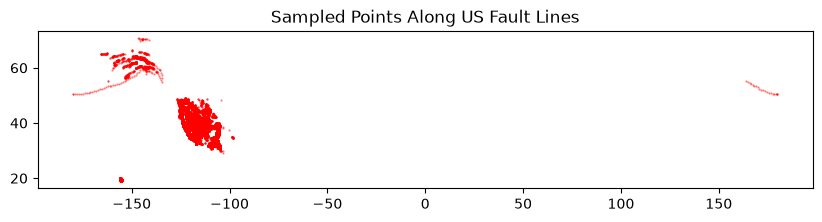

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt

fault_path = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/outputs/Points along faults.shp"
)

faults = gpd.read_file(fault_path)

print("CRS:", faults.crs)
print("Number of points:", len(faults))
print("Geometry types:")
print(faults.geometry.geom_type.value_counts())
print("\nBounds:", faults.total_bounds)

# Display a quick preview
fig, ax = plt.subplots(figsize=(10, 8))

faults.plot(
    ax=ax,
    markersize=0.3,
    color="red",
    alpha=0.5
)

ax.set_title("Sampled Points Along US Fault Lines")
plt.show()

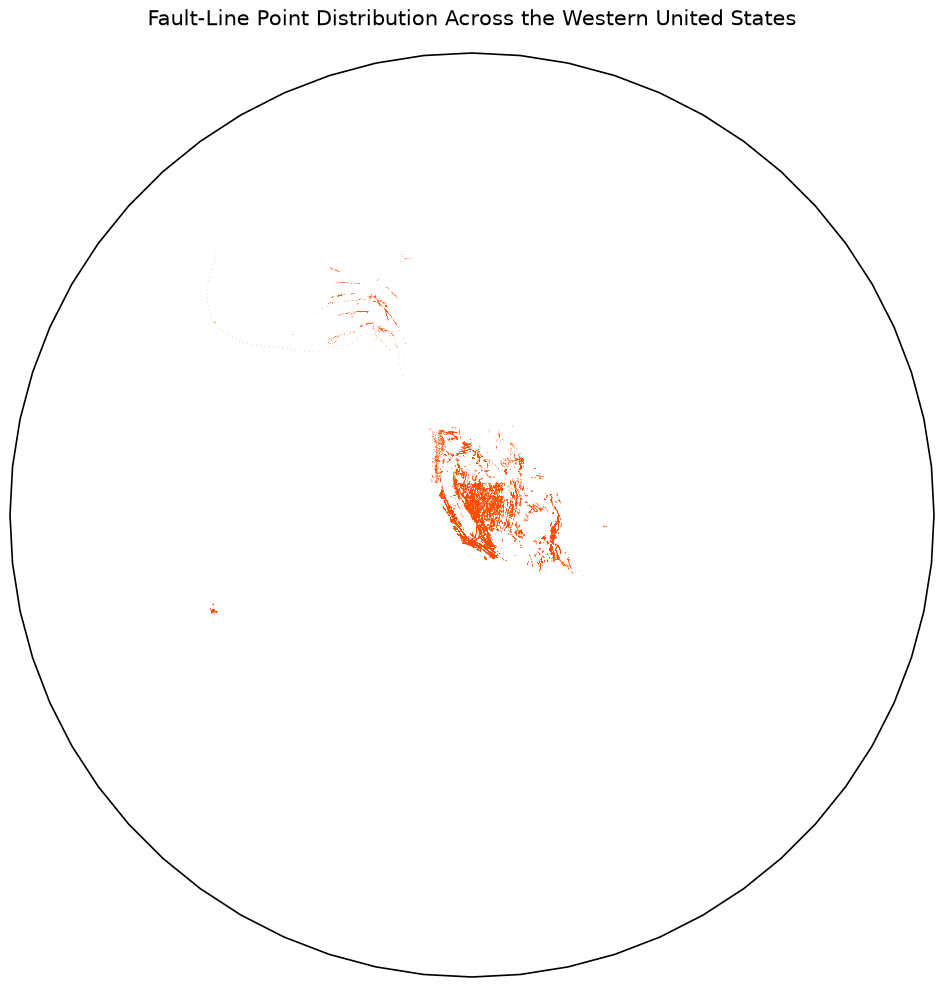

In [3]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

fault_path = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/outputs/Points along faults.shp"
)

faults = gpd.read_file(fault_path)

# Make sure the coordinates are longitude/latitude
faults = faults.to_crs("EPSG:4326")

# Globe-like projection centered on the western United States
ortho = ccrs.Orthographic(
    central_longitude=-119,
    central_latitude=38
)

fig = plt.figure(figsize=(12, 12))

ax = fig.add_subplot(
    1, 1, 1,
    projection=ortho
)

ax.set_global()

# Globe outline
ax.spines["geo"].set_linewidth(1.2)

# Plot the fault points
ax.scatter(
    faults.geometry.x,
    faults.geometry.y,
    transform=ccrs.PlateCarree(),
    s=0.15,
    color="#ff4d00",
    alpha=0.65,
    linewidths=0,
    rasterized=True
)

ax.set_title(
    "Fault-Line Point Distribution Across the Western United States",
    fontsize=15,
    pad=20
)

plt.show()

In [4]:
import os
from getpass import getpass

MAPBOX_TOKEN = getpass("Mapbox token: ")

Mapbox token:  ········


In [5]:
MAPBOX_USERNAME = "sophiameyers"
MAPBOX_STYLE_ID = "cmw04pvs3008t01p89yal70a0"

Status: 200
Size: 96826


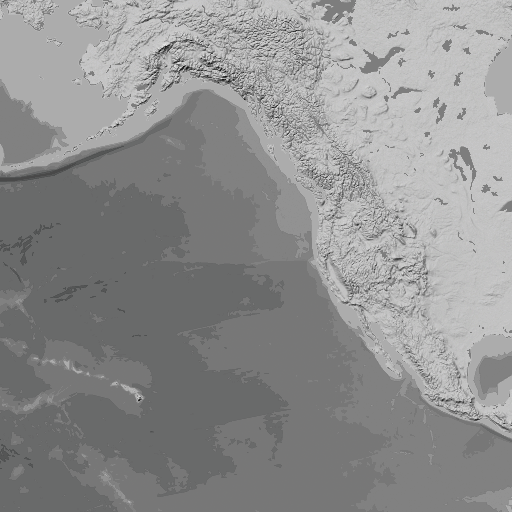

In [6]:
import requests
from PIL import Image
from io import BytesIO
from IPython.display import display

z, x, y = 2, 0, 1

tile_url = (
    f"https://api.mapbox.com/styles/v1/"
    f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/"
    f"tiles/512/{z}/{x}/{y}.png"
)

response = requests.get(
    tile_url,
    params={"access_token": MAPBOX_TOKEN},
    timeout=60
)

print("Status:", response.status_code)
print("Size:", len(response.content))

if response.ok:
    tile = Image.open(BytesIO(response.content)).convert("RGB")
    display(tile)
else:
    print(response.text)

# Fresh

Loading cached Mapbox basemap...
Basemap dimensions: (4096, 4096, 4)
Reprojecting basemap...
Basemap reprojected.
Total fault features: 112809
Original CRS: EPSG:4326


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)


Fault lines in map extent: 112809
Visible fault points: 112898
Fault density calculated.


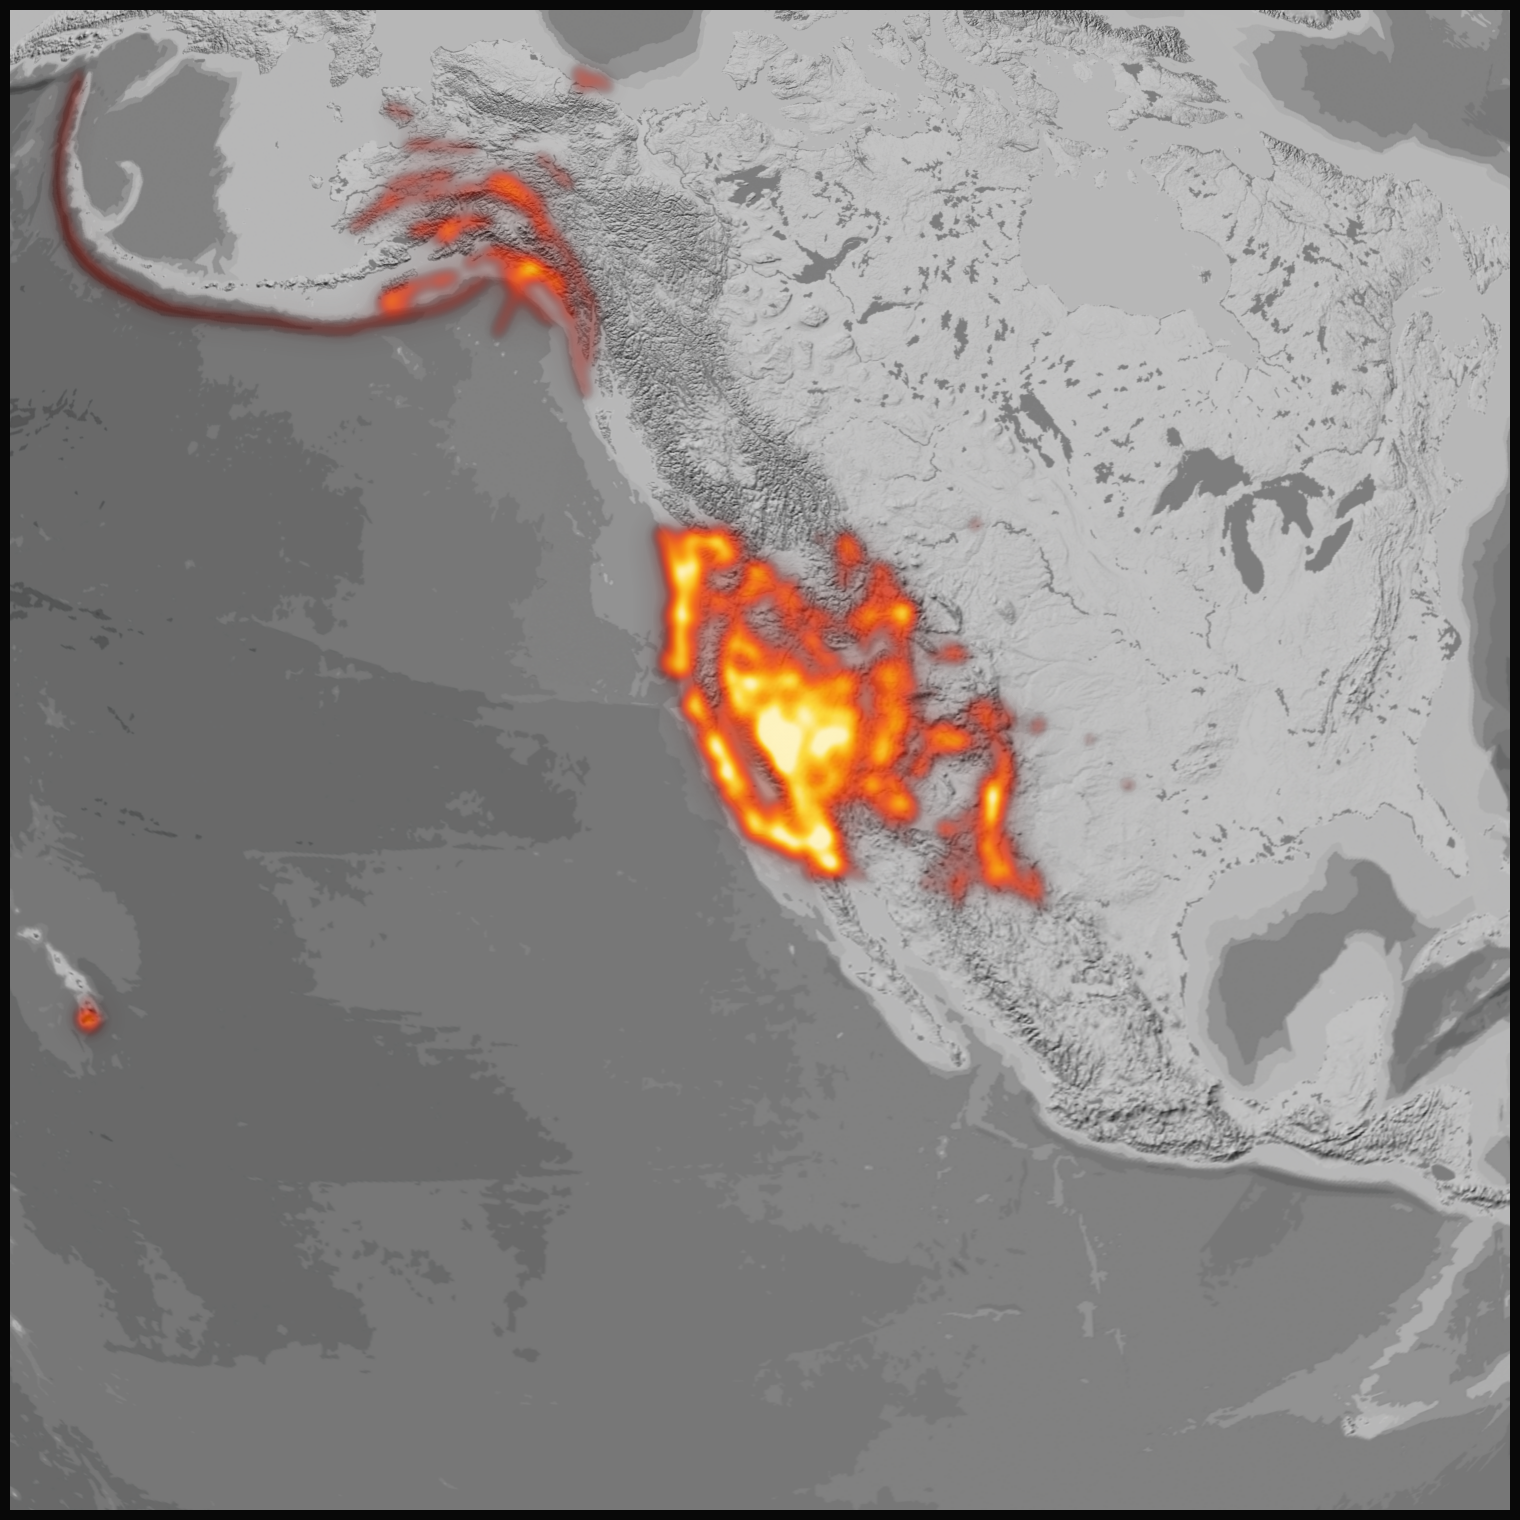

Exported: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/pacific_fault_line_density.png


In [7]:
# ============================================================
# PACIFIC RING OF FIRE — AZIMUTHAL ORTHOGRAPHIC MAP
# ============================================================

# ----------------------------
# 1. IMPORTS
# ----------------------------

import os
import requests
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from io import BytesIO
from PIL import Image
from pathlib import Path
from getpass import getpass

from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
from matplotlib.patches import Circle


# ----------------------------
# 2. MAPBOX SETTINGS
# ----------------------------

MAPBOX_USERNAME = "sophiameyers"

# Use your published custom Mapbox style ID
# If already defined earlier in your notebook, this will reuse it.
MAPBOX_STYLE_ID = globals().get(
    "MAPBOX_STYLE_ID",
    "PASTE_YOUR_STYLE_ID_HERE"
)

# Reuse your existing token, or enter it if it is not defined
if "MAPBOX_TOKEN" not in globals():
    MAPBOX_TOKEN = getpass("Enter your Mapbox access token: ")

# Check that the style ID has been set
if MAPBOX_STYLE_ID == "PASTE_YOUR_STYLE_ID_HERE":
    raise ValueError("Set MAPBOX_STYLE_ID to your published Mapbox style ID.")



# ----------------------------
# 4. ORTHOGRAPHIC PROJECTION
# ----------------------------

center_lon = -120
center_lat = 38

ortho_crs = (
    f"+proj=ortho "
    f"+lat_0={center_lat} "
    f"+lon_0={center_lon} "
    f"+datum=WGS84 "
    f"+units=m "
    f"+no_defs"
)

# Zoomed-in rectangular framing
extent_x = 3_900_000
extent_y = 3_900_000

output_width = 3000
output_height = 3000
# ----------------------------
# 5. DOWNLOAD MAPBOX TILES
# ----------------------------

# Zoom level 3 gives a complete global mosaic using 64 tiles.
# The downloaded mosaic is cached so you do not have to
# download the tiles again every time you rerun the notebook.

z = 3
tile_size = 512
n_tiles = 2 ** z

cache_folder = Path("mapbox_cache")
cache_folder.mkdir(exist_ok=True)

mosaic_cache = cache_folder / f"pacific_basemap_z{z}_{MAPBOX_STYLE_ID}.npy"

if mosaic_cache.exists():

    print("Loading cached Mapbox basemap...")

    basemap = np.load(mosaic_cache)

else:

    print("Downloading Mapbox tiles...")

    basemap = np.zeros(
        (n_tiles * tile_size, n_tiles * tile_size, 4),
        dtype=np.uint8
    )

    for x in range(n_tiles):
        for y in range(n_tiles):

            url = (
                f"https://api.mapbox.com/styles/v1/"
                f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/"
                f"tiles/512/{z}/{x}/{y}.png"
            )

            response = requests.get(
                url,
                params={"access_token": MAPBOX_TOKEN},
                timeout=60
            )

            response.raise_for_status()

            tile = np.array(
                Image.open(BytesIO(response.content)).convert("RGBA")
            )

            basemap[
                y * tile_size:(y + 1) * tile_size,
                x * tile_size:(x + 1) * tile_size
            ] = tile

        print(f"Downloaded column {x + 1}/{n_tiles}")

    np.save(mosaic_cache, basemap)

    print("Basemap cached successfully.")

print("Basemap dimensions:", basemap.shape)


# ----------------------------
# 6. DEFINE SOURCE TRANSFORM
# ----------------------------

web_mercator_limit = 20037508.342789244
world_width = web_mercator_limit * 2

tile_span = world_width / n_tiles
pixel_size = tile_span / tile_size

src_transform = from_origin(
    -web_mercator_limit,
    web_mercator_limit,
    pixel_size,
    pixel_size
)


# ----------------------------
# 7. REPROJECT BASEMAP
# ----------------------------

print("Reprojecting basemap...")

dst_transform = from_origin(
    -extent_x,
    extent_y,
    (2 * extent_x) / output_width,
    (2 * extent_y) / output_height
)

projected = np.zeros(
    (4, output_height, output_width),
    dtype=np.uint8
)

for band in range(3):
    reproject(
        source=basemap[:, :, band],
        destination=projected[band],
        src_transform=src_transform,
        src_crs="EPSG:3857",
        dst_transform=dst_transform,
        dst_crs=ortho_crs,
        resampling=Resampling.bilinear
    )

reproject(
    source=basemap[:, :, 3],
    destination=projected[3],
    src_transform=src_transform,
    src_crs="EPSG:3857",
    dst_transform=dst_transform,
    dst_crs=ortho_crs,
    resampling=Resampling.nearest
)

projected_image = np.moveaxis(projected, 0, -1)

print("Basemap reprojected.")

# ----------------------------
# 8. LOAD AND REPROJECT FAULT LINES
# ----------------------------

from shapely.geometry import box

fault_line_path = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/data/Qfaults_GIS/SHP/"
    "Qfaults_US_Database.shp"
)

fault_lines = gpd.read_file(fault_line_path)

print("Total fault features:", len(fault_lines))
print("Original CRS:", fault_lines.crs)

if fault_lines.crs is None:
    raise ValueError("Fault-line shapefile has no defined CRS.")

fault_lines = fault_lines[
    fault_lines.geometry.notna()
    & ~fault_lines.geometry.is_empty
].copy()

# Keep line geometries
fault_lines = fault_lines[
    fault_lines.geom_type.isin(
        ["LineString", "MultiLineString"]
    )
].copy()

# Reproject to your map projection
fault_lines = fault_lines.to_crs(ortho_crs)

# Clip to map extent
map_boundary = box(
    -extent_x,
    -extent_y,
    extent_x,
    extent_y
)

fault_lines = gpd.clip(
    fault_lines,
    map_boundary
)

fault_lines = fault_lines[
    ~fault_lines.geometry.is_empty
].copy()

print("Fault lines in map extent:", len(fault_lines))

# ----------------------------
# 9. REPROJECT FAULT POINTS
# ----------------------------

transformer = Transformer.from_crs(
    "EPSG:4326",
    ortho_crs,
    always_xy=True
)

fault_x, fault_y = transformer.transform(
    faults.geometry.x.values,
    faults.geometry.y.values
)

faults["map_x"] = fault_x
faults["map_y"] = fault_y

lon = np.radians(faults.geometry.x.values)
lat = np.radians(faults.geometry.y.values)

lon0 = np.radians(center_lon)
lat0 = np.radians(center_lat)

cos_c = (
    np.sin(lat0) * np.sin(lat)
    + np.cos(lat0) * np.cos(lat) * np.cos(lon - lon0)
)

visible = (
    (cos_c >= 0)
    & (np.abs(faults["map_x"]) <= extent_x)
    & (np.abs(faults["map_y"]) <= extent_y)
)

faults_visible = faults.loc[visible].copy()

print("Visible fault points:", len(faults_visible))


# ----------------------------
# 11. CREATE FAULT LINE DENSITY
# ----------------------------

from scipy.ndimage import gaussian_filter
from rasterio.features import rasterize

heatmap_resolution = 2000

pixel_x = (2 * extent_x) / heatmap_resolution
pixel_y = (2 * extent_y) / heatmap_resolution

heatmap_transform = from_origin(
    -extent_x,
    extent_y,
    pixel_x,
    pixel_y
)

# Rasterize fault lines as a presence surface
line_presence = rasterize(
    [(geom, 1) for geom in fault_lines.geometry],
    out_shape=(
        heatmap_resolution,
        heatmap_resolution
    ),
    transform=heatmap_transform,
    fill=0,
    all_touched=True,
    dtype="uint8"
)

# Smooth the surface
density_smooth = gaussian_filter(
    line_presence.astype("float32"),
    sigma=8
)

# Log transformation
density_log = np.log1p(density_smooth)

# Normalize using the 99th percentile
positive_values = density_log[density_log > 0]

if len(positive_values) == 0:
    raise ValueError("No fault lines were rasterized.")

density_max = np.percentile(
    positive_values,
    99
)

density_norm = np.clip(
    density_log / density_max,
    0,
    1
)

print("Fault density calculated.")
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

# ------------------------------------------------------------
# FIRE / LAVA COLOR RAMP
# ------------------------------------------------------------

fire_cmap = LinearSegmentedColormap.from_list(
    "fault_fire",
    [
        (0.00, "#120000"),  # almost black
        (0.12, "#430000"),  # dark red
        (0.28, "#990b00"),  # deep red
        (0.45, "#ed2400"),  # intense red
        (0.62, "#ff5700"),  # orange
        (0.78, "#ff9d00"),  # golden orange
        (0.91, "#ffdb38"),  # yellow
        (1.00, "#fff5c2")   # hot white-yellow
    ],
    N=256
)

# Increase contrast in the density values
fire_density = np.clip(density_norm, 0, 1) ** 0.65

# ------------------------------------------------------------
# CREATE THREE GLOW LAYERS
# ------------------------------------------------------------

# Wide, soft glow
fire_halo = gaussian_filter(fire_density, sigma=24)

# Medium glow
fire_mid = gaussian_filter(fire_density, sigma=10)

# Sharp, concentrated hot areas
fire_core = gaussian_filter(fire_density, sigma=2)

def make_fire_layer(data, threshold, opacity):
    rgba = fire_cmap(np.clip(data, 0, 1))

    alpha = np.clip(
        (data - threshold) / (1 - threshold),
        0, 1
    ) ** 0.8

    rgba[:, :, 3] = alpha * opacity
    return rgba

halo_rgba = make_fire_layer(fire_halo, 0.025, 0.35)
mid_rgba = make_fire_layer(fire_mid, 0.06, 0.65)
core_rgba = make_fire_layer(fire_core, 0.12, 0.95)


# ------------------------------------------------------------
# BASEMAP
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 15), facecolor="#080808")

ax.imshow(
    projected_image,
    extent=[-extent_x, extent_x, -extent_y, extent_y],
    origin="upper"
)

# ------------------------------------------------------------
# FIRE EFFECT — BACK TO FRONT
# ------------------------------------------------------------

ax.imshow(
    halo_rgba,
    extent=[-extent_x, extent_x, -extent_y, extent_y],
    origin="upper",
    interpolation="bilinear"
)

ax.imshow(
    mid_rgba,
    extent=[-extent_x, extent_x, -extent_y, extent_y],
    origin="upper",
    interpolation="bilinear"
)

ax.imshow(
    core_rgba,
    extent=[-extent_x, extent_x, -extent_y, extent_y],
    origin="upper",
    interpolation="bilinear"
)

ax.set_xlim(-extent_x, extent_x)
ax.set_ylim(-extent_y, extent_y)
ax.set_aspect("equal")
ax.axis("off")

fig.patch.set_facecolor("#080808")
ax.set_facecolor("#080808")

plt.tight_layout(pad=0)
plt.show()
# ----------------------------
# 14. EXPORT
# ----------------------------

output_path = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/outputs/"
    "pacific_fault_line_density.png"
)

fig.savefig(
    output_path,
    dpi=300,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight",
    pad_inches=0
)

print("Exported:", output_path)

Loading cached Mapbox basemap...
Basemap dimensions: (4096, 4096, 4)
Reprojecting basemap...
Basemap reprojected.
Loading fault-line geometries...
Total fault features: 112809
Original CRS: EPSG:4326


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)


Fault lines in map extent: 112809
Transect latitude: 39.0
Transect longitude range: -124.5 to -74.5
Creating fault-density surface...
Fault density calculated.
Calculating east-west fault cross-section...


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)


Cross-section calculations complete.
Total fault length in corridors: 3804.32 km
Total fault intersections: 18792


/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_70059/722254746.py:756: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.3)


Saved transparent SVG: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/pacific_ring_of_fire_east_west_transect.svg


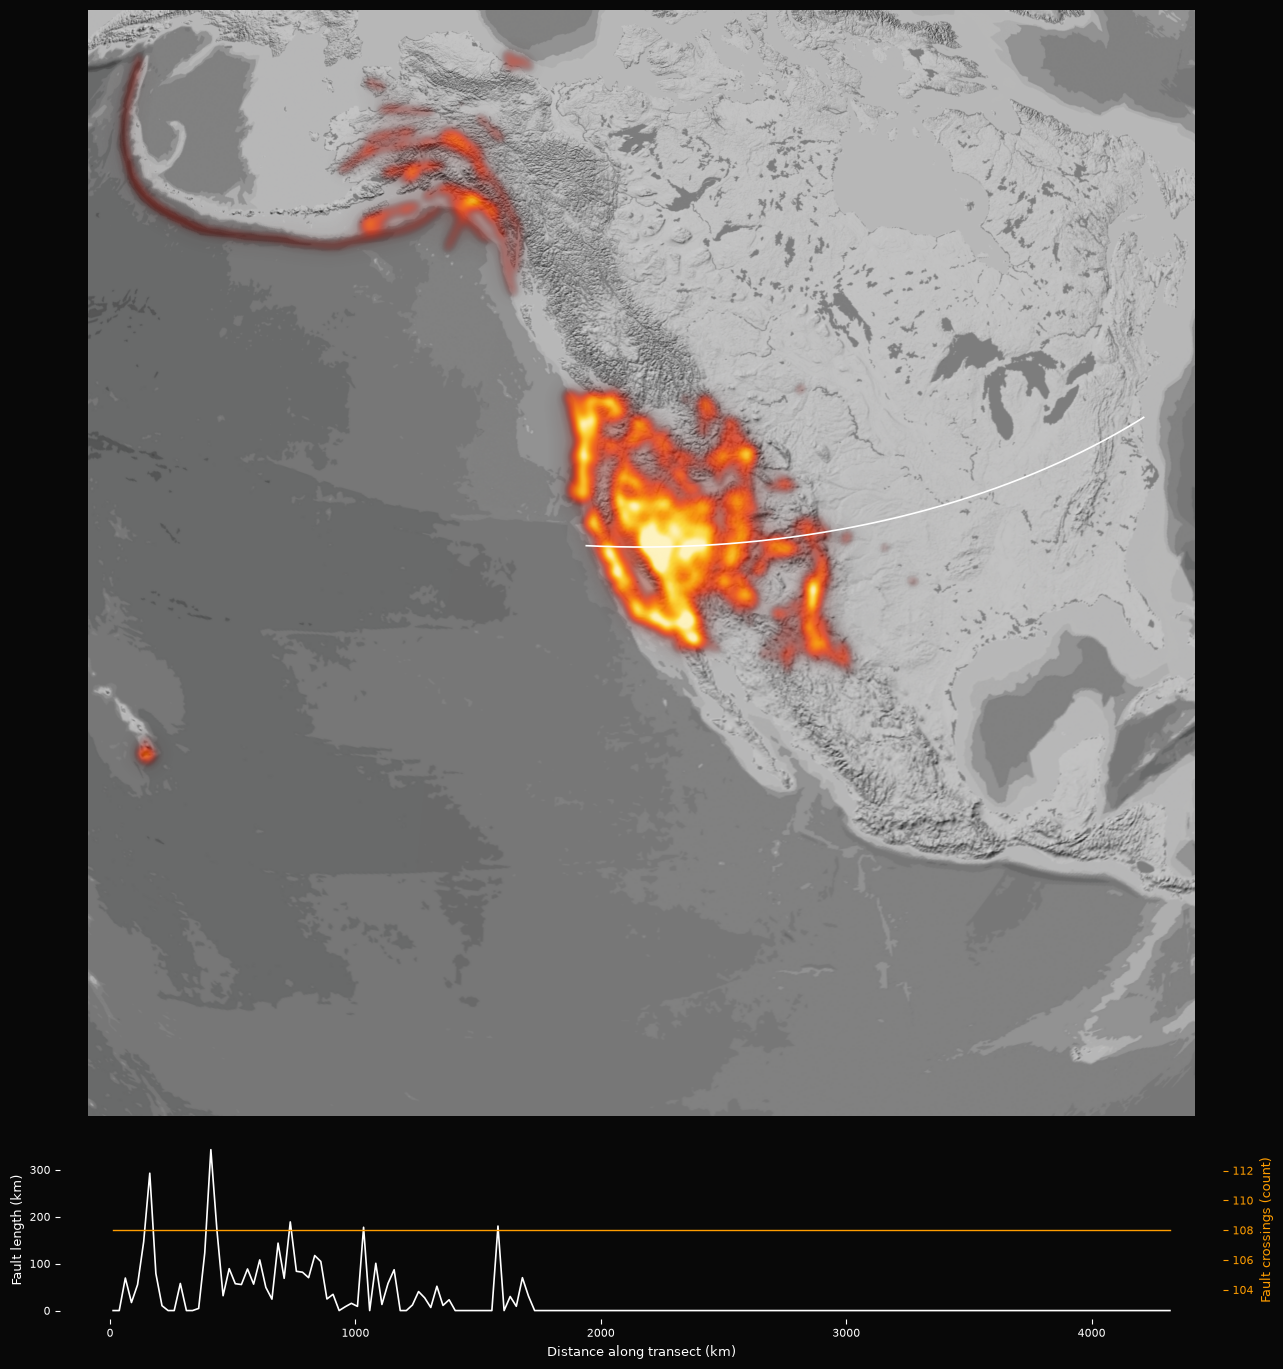

In [9]:
# ============================================================
# PACIFIC RING OF FIRE — ORTHOGRAPHIC FIRE MAP
# WITH DIAGONAL FAULT-LINE CROSS-SECTION
# ============================================================


# ------------------------------------------------------------
# 1. IMPORTS
# ------------------------------------------------------------

import os
import requests
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from io import BytesIO
from PIL import Image
from pathlib import Path
from getpass import getpass

from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling
from rasterio.features import rasterize

from pyproj import Transformer, Geod, CRS

from shapely.geometry import box
from shapely.ops import transform as shapely_transform

from scipy.ndimage import gaussian_filter
from matplotlib.colors import LinearSegmentedColormap


# ------------------------------------------------------------
# 2. MAPBOX SETTINGS
# ------------------------------------------------------------

MAPBOX_USERNAME = "sophiameyers"

MAPBOX_STYLE_ID = globals().get(
    "MAPBOX_STYLE_ID",
    "cmh9dpvwu00ay01sq35bb44mx"
)

if "MAPBOX_TOKEN" not in globals():
    MAPBOX_TOKEN = getpass("Enter your Mapbox access token: ")


# ------------------------------------------------------------
# 3. FILE PATHS
# ------------------------------------------------------------

project_dir = Path(
    "/Users/sophiameyers/Documents/GitHub/30-day-mapping"
)

fault_line_path = (
    project_dir /
    "data/Qfaults_GIS/SHP/Qfaults_US_Database.shp"
)

cache_folder = project_dir / "mapbox_cache"
cache_folder.mkdir(exist_ok=True)

output_folder = project_dir / "outputs"
output_folder.mkdir(exist_ok=True)


# ------------------------------------------------------------
# 4. ORTHOGRAPHIC PROJECTION
# ------------------------------------------------------------

center_lon = -120
center_lat = 38

ortho_crs = (
    f"+proj=ortho "
    f"+lat_0={center_lat} "
    f"+lon_0={center_lon} "
    f"+datum=WGS84 "
    f"+units=m "
    f"+no_defs"
)

extent_x = 3_900_000
extent_y = 3_900_000

output_width = 3000
output_height = 3000


# ------------------------------------------------------------
# 5. DOWNLOAD MAPBOX TILES
# ------------------------------------------------------------

z = 3
tile_size = 512
n_tiles = 2 ** z

mosaic_cache = (
    cache_folder /
    f"pacific_basemap_z{z}_{MAPBOX_STYLE_ID}.npy"
)

if mosaic_cache.exists():

    print("Loading cached Mapbox basemap...")

    basemap = np.load(mosaic_cache)

else:

    print("Downloading Mapbox tiles...")

    basemap = np.zeros(
        (n_tiles * tile_size, n_tiles * tile_size, 4),
        dtype=np.uint8
    )

    for x in range(n_tiles):

        for y in range(n_tiles):

            url = (
                f"https://api.mapbox.com/styles/v1/"
                f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/"
                f"tiles/512/{z}/{x}/{y}.png"
            )

            response = requests.get(
                url,
                params={"access_token": MAPBOX_TOKEN},
                timeout=60
            )

            response.raise_for_status()

            tile = np.array(
                Image.open(
                    BytesIO(response.content)
                ).convert("RGBA")
            )

            basemap[
                y * tile_size:(y + 1) * tile_size,
                x * tile_size:(x + 1) * tile_size
            ] = tile

        print(f"Downloaded column {x + 1}/{n_tiles}")

    np.save(mosaic_cache, basemap)

    print("Basemap cached successfully.")

print("Basemap dimensions:", basemap.shape)


# ------------------------------------------------------------
# 6. DEFINE SOURCE TRANSFORM
# ------------------------------------------------------------

web_mercator_limit = 20037508.342789244
world_width = web_mercator_limit * 2

tile_span = world_width / n_tiles
pixel_size = tile_span / tile_size

src_transform = from_origin(
    -web_mercator_limit,
    web_mercator_limit,
    pixel_size,
    pixel_size
)


# ------------------------------------------------------------
# 7. REPROJECT BASEMAP
# ------------------------------------------------------------

print("Reprojecting basemap...")

dst_transform = from_origin(
    -extent_x,
    extent_y,
    (2 * extent_x) / output_width,
    (2 * extent_y) / output_height
)

projected = np.zeros(
    (4, output_height, output_width),
    dtype=np.uint8
)

for band in range(3):

    reproject(
        source=basemap[:, :, band],
        destination=projected[band],
        src_transform=src_transform,
        src_crs="EPSG:3857",
        dst_transform=dst_transform,
        dst_crs=ortho_crs,
        resampling=Resampling.bilinear
    )

reproject(
    source=basemap[:, :, 3],
    destination=projected[3],
    src_transform=src_transform,
    src_crs="EPSG:3857",
    dst_transform=dst_transform,
    dst_crs=ortho_crs,
    resampling=Resampling.nearest
)

projected_image = np.moveaxis(
    projected,
    0,
    -1
)

print("Basemap reprojected.")


# ------------------------------------------------------------
# 8. LOAD FAULT LINES
# ------------------------------------------------------------

print("Loading fault-line geometries...")

fault_lines_geo = gpd.read_file(
    fault_line_path
)

print("Total fault features:", len(fault_lines_geo))
print("Original CRS:", fault_lines_geo.crs)

if fault_lines_geo.crs is None:
    raise ValueError(
        "Fault-line shapefile has no defined CRS."
    )

fault_lines_geo = fault_lines_geo[
    fault_lines_geo.geometry.notna()
    & ~fault_lines_geo.geometry.is_empty
].copy()

fault_lines_geo = fault_lines_geo[
    fault_lines_geo.geom_type.isin(
        ["LineString", "MultiLineString"]
    )
].copy()

# Keep geographic version for distance calculations
fault_lines_geo = fault_lines_geo.to_crs("EPSG:4326")

# Reproject a separate copy for the map
fault_lines = fault_lines_geo.to_crs(ortho_crs)

# Clip to map extent
map_boundary = box(
    -extent_x,
    -extent_y,
    extent_x,
    extent_y
)

fault_lines = gpd.clip(
    fault_lines,
    map_boundary
)

fault_lines = fault_lines[
    ~fault_lines.geometry.is_empty
].copy()

print("Fault lines in map extent:", len(fault_lines))


# ------------------------------------------------------------
# 9. DEFINE EAST-WEST TRANSECT ACROSS CONTINENTAL US
# ------------------------------------------------------------

# Constant latitude
transect_latitude = 39.0

# Longitude endpoints
start_lon = -124.5
end_lon = -74.5

start_lat = transect_latitude
end_lat = transect_latitude

# Generate a straight line of constant latitude
transect_lon = np.linspace(
    start_lon,
    end_lon,
    1000
)

transect_lat = np.full(
    len(transect_lon),
    transect_latitude
)

# Transform to Orthographic coordinates
transformer = Transformer.from_crs(
    "EPSG:4326",
    ortho_crs,
    always_xy=True
)

transect_x, transect_y = transformer.transform(
    transect_lon,
    transect_lat
)

print("Transect latitude:", transect_latitude)
print("Transect longitude range:", start_lon, "to", end_lon)
# ------------------------------------------------------------
# 10. CREATE FAULT-LINE DENSITY RASTER
# ------------------------------------------------------------

print("Creating fault-density surface...")

heatmap_resolution = 2000

pixel_x = (2 * extent_x) / heatmap_resolution
pixel_y = (2 * extent_y) / heatmap_resolution

heatmap_transform = from_origin(
    -extent_x,
    extent_y,
    pixel_x,
    pixel_y
)

line_presence = rasterize(
    [(geom, 1) for geom in fault_lines.geometry],
    out_shape=(
        heatmap_resolution,
        heatmap_resolution
    ),
    transform=heatmap_transform,
    fill=0,
    all_touched=True,
    dtype="uint8"
)

density_smooth = gaussian_filter(
    line_presence.astype("float32"),
    sigma=8
)

density_log = np.log1p(density_smooth)

positive_values = density_log[
    density_log > 0
]

if len(positive_values) == 0:
    raise ValueError(
        "No fault lines were rasterized."
    )

density_max = np.percentile(
    positive_values,
    99
)

density_norm = np.clip(
    density_log / density_max,
    0,
    1
)

print("Fault density calculated.")


# ------------------------------------------------------------
# 11. FIRE / LAVA COLOR RAMP
# ------------------------------------------------------------

fire_cmap = LinearSegmentedColormap.from_list(
    "fault_fire",
    [
        (0.00, "#120000"),
        (0.12, "#430000"),
        (0.28, "#990b00"),
        (0.45, "#ed2400"),
        (0.62, "#ff5700"),
        (0.78, "#ff9d00"),
        (0.91, "#ffdb38"),
        (1.00, "#fff5c2")
    ],
    N=256
)

fire_density = np.clip(
    density_norm,
    0,
    1
) ** 0.65

fire_halo = gaussian_filter(
    fire_density,
    sigma=24
)

fire_mid = gaussian_filter(
    fire_density,
    sigma=10
)

fire_core = gaussian_filter(
    fire_density,
    sigma=2
)


def make_fire_layer(data, threshold, opacity):

    rgba = fire_cmap(
        np.clip(data, 0, 1)
    )

    alpha = np.clip(
        (data - threshold) / (1 - threshold),
        0,
        1
    ) ** 0.8

    rgba[:, :, 3] = alpha * opacity

    return rgba


halo_rgba = make_fire_layer(
    fire_halo,
    0.025,
    0.35
)

mid_rgba = make_fire_layer(
    fire_mid,
    0.06,
    0.65
)

core_rgba = make_fire_layer(
    fire_core,
    0.12,
    0.95
)

# ------------------------------------------------------------
# 12. PREPARE FAULT-LINE CROSS-SECTION
# ------------------------------------------------------------

from shapely.geometry import LineString, Point
from shapely.ops import unary_union

print("Calculating east-west fault cross-section...")

# Use the original geographic fault geometries.
# Do not use the Orthographic-clipped map layer.

faults_geo = fault_lines_geo.to_crs("EPSG:4326")

# Use a local projected CRS for measurements
mid_lon = (start_lon + end_lon) / 2
mid_lat = transect_latitude

local_crs = CRS.from_proj4(
    f"+proj=aeqd "
    f"+lat_0={mid_lat} "
    f"+lon_0={mid_lon} "
    f"+datum=WGS84 "
    f"+units=m +no_defs"
)

local_transformer = Transformer.from_crs(
    "EPSG:4326",
    local_crs,
    always_xy=True
)

# Transform transect coordinates
transect_local_x, transect_local_y = local_transformer.transform(
    transect_lon,
    transect_lat
)

transect_local = LineString(
    zip(transect_local_x, transect_local_y)
)

# Project fault geometries
faults_local = faults_geo.to_crs(local_crs)

# ------------------------------------------------------------
# 13. SET UP TRANSECT BINS
# ------------------------------------------------------------

# Each profile segment represents 25 km
bin_size = 25_000

# Corridor extends 12.5 km north and south of transect
corridor_width = 12_500

transect_length = transect_local.length

n_bins = int(
    np.ceil(transect_length / bin_size)
)

distances_along = []
fault_lengths = []
fault_crossings = []

# ------------------------------------------------------------
# 14. MEASURE FAULT LENGTH AND COUNT INTERSECTIONS
# ------------------------------------------------------------

for i in range(n_bins):

    s0 = i * transect_length / n_bins
    s1 = (i + 1) * transect_length / n_bins

    # Position the bin along the transect
    p0 = transect_local.interpolate(s0)
    p1 = transect_local.interpolate(s1)

    # Build a corridor around this transect segment
    segment = LineString([p0, p1]).buffer(
        corridor_width,
        cap_style=2
    )

    # Measure total fault length inside corridor
    total_length = 0

    # Count actual fault intersections with centerline
    total_crossings = 0

    for geom in faults_local.geometry:

        if geom is None or geom.is_empty:
            continue

        # Fault length within the corridor
        if geom.intersects(segment):

            clipped = geom.intersection(segment)

            if clipped.geom_type == "LineString":
                total_length += clipped.length

            elif clipped.geom_type in [
                "MultiLineString",
                "GeometryCollection"
            ]:

                for part in clipped.geoms:

                    if part.geom_type == "LineString":
                        total_length += part.length

        # Count intersections with the transect centerline
        if geom.intersects(transect_local):

            intersection = geom.intersection(
                transect_local
            )

            if intersection.geom_type == "Point":
                total_crossings += 1

            elif intersection.geom_type == "MultiPoint":
                total_crossings += len(intersection.geoms)

            elif intersection.geom_type == "GeometryCollection":
                total_crossings += sum(
                    1
                    for part in intersection.geoms
                    if part.geom_type == "Point"
                )

    distances_along.append(
        (s0 + s1) / 2 / 1000
    )

    fault_lengths.append(
        total_length / 1000
    )

    fault_crossings.append(
        total_crossings
    )


distances_along = np.array(distances_along)
fault_lengths = np.array(fault_lengths)
fault_crossings = np.array(fault_crossings)

print("Cross-section calculations complete.")
print("Total fault length in corridors:", round(fault_lengths.sum(), 2), "km")
print("Total fault intersections:", fault_crossings.sum())
# ------------------------------------------------------------
# 15. FINAL MAP + CROSS-SECTION
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(15, 17),
    facecolor="#080808"
)

gs = fig.add_gridspec(
    2,
    1,
    height_ratios=[5, 0.8],
    hspace=0.04
)

ax = fig.add_subplot(gs[0])
ax_profile = fig.add_subplot(gs[1])


# MAP
ax.imshow(
    projected_image,
    extent=[
        -extent_x,
        extent_x,
        -extent_y,
        extent_y
    ],
    origin="upper"
)

ax.imshow(
    halo_rgba,
    extent=[
        -extent_x,
        extent_x,
        -extent_y,
        extent_y
    ],
    origin="upper",
    interpolation="bilinear"
)

ax.imshow(
    mid_rgba,
    extent=[
        -extent_x,
        extent_x,
        -extent_y,
        extent_y
    ],
    origin="upper",
    interpolation="bilinear"
)

ax.imshow(
    core_rgba,
    extent=[
        -extent_x,
        extent_x,
        -extent_y,
        extent_y
    ],
    origin="upper",
    interpolation="bilinear"
)

# White east-west transect
ax.plot(
    transect_x,
    transect_y,
    color="white",
    linewidth=1.2,
    zorder=10
)

ax.set_xlim(-extent_x, extent_x)
ax.set_ylim(-extent_y, extent_y)
ax.set_aspect("equal")
ax.axis("off")
ax.set_facecolor("#080808")


# PROFILE: FAULT LENGTH
ax_profile.plot(
    distances_along,
    fault_lengths,
    color="white",
    linewidth=1.2
)

ax_profile.set_facecolor("#080808")

ax_profile.set_xlabel(
    "Distance along transect (km)",
    color="white",
    fontsize=9
)

ax_profile.set_ylabel(
    "Fault length (km)",
    color="white",
    fontsize=9
)

ax_profile.tick_params(
    axis="both",
    colors="white",
    labelsize=8
)

# SECOND AXIS: FAULT CROSSINGS
ax_crossings = ax_profile.twinx()

ax_crossings.plot(
    distances_along,
    fault_crossings,
    color="#ff9d00",
    linewidth=1.0
)

ax_crossings.set_ylabel(
    "Fault crossings (count)",
    color="#ff9d00",
    fontsize=9
)

ax_crossings.tick_params(
    axis="y",
    colors="#ff9d00",
    labelsize=8
)

# Minimal styling
for spine in ax_profile.spines.values():
    spine.set_visible(False)

for spine in ax_crossings.spines.values():
    spine.set_visible(False)

ax_profile.grid(False)
ax_crossings.grid(False)

fig.patch.set_facecolor("#080808")

plt.tight_layout(pad=0.3)

svg_path = output_folder / "pacific_ring_of_fire_east_west_transect.svg"

plt.savefig(
    svg_path,
    format="svg",
    transparent=True,
    bbox_inches="tight",
    pad_inches=0
)

print("Saved transparent SVG:", svg_path)